## CIFAR10 Image Classification using CNN

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

100%|██████████| 170M/170M [1:04:13<00:00, 44.2kB/s] 


In [17]:
len(train_dataset), len(test_dataset)

(50000, 10000)

In [18]:
batch_size = 100

# Data loaders
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

In [19]:
for i, (images, labels) in enumerate(train_loader):
    print(images.shape)
    print(labels.shape)
    break

torch.Size([100, 3, 32, 32])
torch.Size([100])


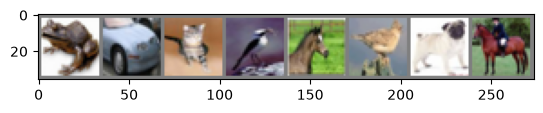

In [20]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# show images
imshow(torchvision.utils.make_grid(images[:8]))

In [21]:
labels[:8]

tensor([6, 1, 3, 2, 7, 2, 5, 7])

In [22]:
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [23]:
[classes[i] for i in labels[:8]]

['frog', 'car', 'cat', 'bird', 'horse', 'bird', 'dog', 'horse']

### Train a NN

In [24]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=(3,3), padding='same'),  # Output: (32, 32, 32)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2)),        # Output: (32, 16, 16)
            
            nn.Conv2d(32, 64, kernel_size=(3,3)),             # Output: (64, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))         # Output: (64, 7, 7)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),                                # Flatten to (64 * 7 * 7 = 3136)
            nn.Linear(64 * 7 * 7, 600),                  # Corrected input size
            nn.ReLU(),
            nn.Linear(600, 120),
            nn.ReLU(),
            nn.Linear(120, 10)
        )
        
    def forward(self, x):
        x = self.network(x)
        x = self.fc_layers(x)
        return x

In [25]:
model = CNN()
dummy_input = torch.randn(1, 3, 32, 32)  # Single example with CIFAR-10 dimensions
output = model(dummy_input)
print("Output shape:", output.shape)  # Should be [1, 10]

Output shape: torch.Size([1, 10])


In [26]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [27]:
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.5631
Epoch [1/10], Step [200/500], Loss: 1.3994
Epoch [1/10], Step [300/500], Loss: 1.3530
Epoch [1/10], Step [400/500], Loss: 1.3248
Epoch [1/10], Step [500/500], Loss: 0.9186
Epoch [2/10], Step [100/500], Loss: 1.1626
Epoch [2/10], Step [200/500], Loss: 1.0129
Epoch [2/10], Step [300/500], Loss: 0.8559
Epoch [2/10], Step [400/500], Loss: 0.8034
Epoch [2/10], Step [500/500], Loss: 0.9226
Epoch [3/10], Step [100/500], Loss: 1.0112
Epoch [3/10], Step [200/500], Loss: 0.8149
Epoch [3/10], Step [300/500], Loss: 0.7625
Epoch [3/10], Step [400/500], Loss: 0.8805
Epoch [3/10], Step [500/500], Loss: 0.7096
Epoch [4/10], Step [100/500], Loss: 0.5296
Epoch [4/10], Step [200/500], Loss: 0.5650
Epoch [4/10], Step [300/500], Loss: 0.7043
Epoch [4/10], Step [400/500], Loss: 0.6314
Epoch [4/10], Step [500/500], Loss: 0.5089
Epoch [5/10], Step [100/500], Loss: 0.5147
Epoch [5/10], Step [200/500], Loss: 0.4285
Epoch [5/10], Step [300/500], Loss: 0.5648
Epoch [5/10